In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pvlib
import seaborn as sns
import xarray as xr
from pvlib.location import Location
from pyproj import Transformer

sys.path.append("../..")
from src.conversion_energy.pv import (
    NORMALISED_ROOFTOP_PV_CONFIGURATION,
)

sns.set_style("whitegrid", {"grid.color": ".93"})

In [3]:
paths = json.load(open("../../paths_so4.json"))

path_data_analysis = Path(paths["path_data_analysis"])
path_data_processed = Path(paths["path_data_processed"])

path_energy_ch = path_data_processed / "energy" / "ch"
path_energy_europe = path_data_processed / "energy" / "europe"

# Functions

In [4]:
azimuths = {"E": 90, "SE": 135, "S": 180, "SW": 225, "W": 270, "N": 0}

## xarray

In [5]:
def compute_hourly_profile(lat, lon, doy, tilt, azimuth):
    """
    Returns a normalized clear-sky PV profile (length 24) for a given lat, lon, and DOY.
    """
    date = pd.Timestamp('2050-01-01') + pd.Timedelta(days=doy - 1)
    times = pd.date_range(date, periods=24, freq='h', tz='UTC')

    location = Location(lat, lon, tz='UTC')
    solpos = location.get_solarposition(times)
    clearsky = location.get_clearsky(times, model='ineichen')

    # Assume fixed tilt = latitude, azimuth = 180 (south)
    poa = pvlib.irradiance.get_total_irradiance(
        surface_tilt=tilt,
        surface_azimuth=azimuth,
        dni=clearsky['dni'],
        ghi=clearsky['ghi'],
        dhi=clearsky['dhi'],
        solar_zenith=solpos['apparent_zenith'],
        solar_azimuth=solpos['azimuth']
    )

    pv_profile = poa['poa_global'].clip(lower=0).values
    total = pv_profile.sum()
    if total == 0:
        return np.zeros(24)
    return pv_profile / total

In [6]:
def generate_all_profiles(lat_vals, lon_vals, tilt, azimuth):
    days = np.arange(1, 367)  # 1–366
    lat_coords, lon_coords, day_coords = np.meshgrid(lat_vals, lon_vals, days, indexing='ij')

    def profile_func(lat, lon, doy):
        return compute_hourly_profile(lat.item(), lon.item(), int(doy.item()), tilt, azimuth)


    # Use map_blocks over a 3D array (lat, lon, day)
    profile_array = xr.apply_ufunc(
        profile_func,
        xr.DataArray(lat_coords, dims=['lat', 'lon', 'day']),
        xr.DataArray(lon_coords, dims=['lat', 'lon', 'day']),
        xr.DataArray(day_coords, dims=['lat', 'lon', 'day']),
        input_core_dims=[[], [], []],
        output_core_dims=[['hour']],
        vectorize=True,
        dask='parallelized',
        output_dtypes=[float],
        dask_gufunc_kwargs={'output_sizes': {'hour': 24}},
    )

    profile_array = profile_array.assign_coords(hour=np.arange(24))
    return profile_array  # dims: lat, lon, day, hour


In [7]:
def disaggregate_pv(pv_3h: xr.DataArray, profile_ds: xr.DataArray) -> xr.DataArray:
    """
    Disaggregate 3-hourly PV data to hourly values using a profile dataset.
    Fully Dask/xarray compatible. No pandas.

    Parameters:
        pv_3h: xarray.DataArray [time, lat, lon] — 3-hour averages (centered)
        profile_ds: xarray.DataArray [lat, lon, dayofyear, hour] — normalized hourly PV profiles

    Returns:
        pv_hourly: xarray.DataArray [time, lat, lon] — hourly PV values
    """
    # Step 1: Create new hourly times: center -1h, center, center +1h
    offsets = xr.DataArray([-1, 0, 1], dims="offset")
    time_hr = pv_3h.time + offsets * np.timedelta64(1, 'h')  # shape (time, offset)

    # Flatten new hourly time dimension
    new_time = time_hr.stack(sample=("time", "offset")).dropna("sample")

    # Step 2: Repeat PV values over 3 hours
    pv_expanded = pv_3h.expand_dims(offset=offsets).transpose("time", "offset", "lat", "lon")
    pv_expanded = pv_expanded.stack(sample=("time", "offset"))

    # Match time with expanded PV
    pv_expanded = pv_expanded.assign_coords(time=new_time)

    # Step 3: Get day of year and hour of day
    doy = pv_expanded["time.dt.dayofyear"]
    hour = pv_expanded["time.dt.hour"]

    # Step 4: Select weights from profile_ds
    weights = profile_ds.sel(day=doy, hour=hour, method="nearest")  # dims: sample, lat, lon

    # Stack to match pv_expanded dims
    weights = weights.transpose("sample", "lat", "lon")

    # Step 5: Normalize weights across the 3-hour window
    # Group by original timestep (unstack sample)
    pv_expanded = pv_expanded.unstack("sample")
    weights = weights.unstack("sample")

    weight_sum = weights.sum("offset")
    weights = weights / weight_sum

    # Step 6: Scale by original 3h average * 3 (since it's average)
    pv_hourly = pv_expanded * weights * 3  # Now in units of hourly energy

    # Step 7: Collapse offset dimension into time
    pv_hourly = pv_hourly.stack(time=("time", "offset")).dropna("time")

    return pv_hourly


## pandas

In [8]:
# def compute_hourly_profile_pd(lat, lon, doy, tilt, azimuth):
#     """
#     Returns a normalized clear-sky PV profile (length 24) for a given lat, lon, and DOY.
#     Output: pandas Series indexed by hour.
#     """
#     date = pd.Timestamp('2050-01-01') + pd.Timedelta(days=doy - 1)
#     times = pd.date_range(date, periods=24, freq='h', tz='UTC')

#     location = Location(lat, lon, tz='UTC')
#     solpos = location.get_solarposition(times)
#     clearsky = location.get_clearsky(times, model='ineichen')

#     poa = pvlib.irradiance.get_total_irradiance(
#         surface_tilt=tilt,
#         surface_azimuth=azimuth,
#         dni=clearsky['dni'],
#         ghi=clearsky['ghi'],
#         dhi=clearsky['dhi'],
#         solar_zenith=solpos['apparent_zenith'],
#         solar_azimuth=solpos['azimuth']
#     )

#     pv_profile = poa['poa_global'].clip(lower=0).values
#     total = pv_profile.sum()
#     if total == 0:
#         return pd.Series(np.zeros(24), index=times)
#     return pd.Series(pv_profile / total, index=times)


# def generate_all_profiles_pd(lat_vals, lon_vals, tilt, azimuth):
#     """
#     Returns a pandas DataFrame with MultiIndex (lat, lon, day, hour) and values as normalized PV profile.
#     """
#     records = []
#     for lat in lat_vals:
#         for lon in lon_vals:
#             for day in range(1, 366):
#                 profile = compute_hourly_profile_pd(lat, lon, day, tilt, azimuth)
#                 for hour, value in profile.items():
#                     records.append((lat, lon, hour, value))
#     df = pd.DataFrame(records, columns=["lat", "lon", "time", "profile"])
#     df.set_index(["lat", "lon", "time"], inplace=True)
#     return df


In [9]:
def fast_hourly_profile_pd(lat, lon, tilt, azimuth):
    """
    Returns a pandas DataFrame with index as UTC timestamps and column 'profile'.
    Vectorized for all hours in a year.
    """
    base = pd.Timestamp('2050-01-01', tz='UTC')
    times = pd.date_range(base, periods=365*24, freq='h', tz='UTC')

    location = Location(lat, lon, tz='UTC')
    solpos = location.get_solarposition(times)
    clearsky = location.get_clearsky(times, model='ineichen')

    poa = pvlib.irradiance.get_total_irradiance(
        surface_tilt=tilt,
        surface_azimuth=azimuth,
        dni=clearsky['dni'].values,
        ghi=clearsky['ghi'].values,
        dhi=clearsky['dhi'].values,
        solar_zenith=solpos['apparent_zenith'].values,
        solar_azimuth=solpos['azimuth'].values
    )

    pv_profile = np.clip(poa['poa_global'], 0, None)
    df = pd.DataFrame({'time': times, 'profile': pv_profile})
    # Normalize per day
    df['day'] = df['time'].dt.dayofyear
    df['profile'] = df.groupby('day')['profile'].transform(lambda x: x / x.sum() if x.sum() > 0 else 0)
    df.set_index('time', inplace=True)
    df.drop(columns='day', inplace=True)
    return df

def fast_generate_all_profiles_pd(lat_vals, lon_vals, tilt, azimuth):
    """
    Returns a pandas DataFrame with MultiIndex (lat, lon, time) and column 'profile'.
    Vectorized for all locations.
    """
    records = []
    for lat in lat_vals:
        for lon in lon_vals:
            df = fast_hourly_profile_pd(lat, lon, tilt, azimuth)
            df = df.reset_index()
            df['lat'] = lat
            df['lon'] = lon
            records.append(df)
    df_all = pd.concat(records, ignore_index=True)
    df_all.set_index(['lat', 'lon', 'time'], inplace=True)
    return df_all[['profile']]


In [11]:
import calendar


def disaggregate_pv_pd(pv_3h_df, profile_df, config):
    """
    Disaggregate 3-hourly PV data to hourly values using clear-sky profiles.
    pv_3h_df: DataFrame with ['time', 'pv']
    profile_df: DataFrame with ['time', ...pv_columns..., 'dayofyear']
    config: str, e.g. 'tilt-80_W'
    Returns: DataFrame with ['time', 'pv_hourly']
    """
    results = []
    pv_3h_df = pv_3h_df.copy()
    pv_3h_df['time'] = pd.to_datetime(pv_3h_df['time'])
    isleap = calendar.isleap(pv_3h_df['time'].dt.year.iloc[0])
    if isleap:
        pv_3h_df['time'] = pv_3h_df['time'].apply(lambda x: x.replace(year=x.year - 1))

    if "dayofyear" not in profile_df.columns:
        # Add dayofyear column if not present
        profile_df['dayofyear'] = (profile_df.index // 24) + 1

    for idx, row in pv_3h_df.iterrows():
        time_center = row['time']
        pv_val = row['pv']

        # Create 3 hourly times: center-1h, center, center+1h
        times = [time_center + pd.Timedelta(hours=offset) for offset in [-1, 0, 1]]
        weights = []
        for t in times:
            hour_of_year = t.hour + (t.dayofyear - 1) * 24
            mask = (profile_df['time'] == hour_of_year) & (profile_df['dayofyear'] == t.dayofyear)
            if mask.any():
                w = profile_df.loc[mask, config].values[0]
            else:
                print(f"Warning: No profile found for time {t} and config {config}. Using weight 0.")
                w = 0
            weights.append(w)
        weight_sum = sum(weights)
        weights = [w / weight_sum if weight_sum > 0 else 0 for w in weights]

        for t, w in zip(times, weights):
            results.append({'time': t, 'pv_hourly': pv_val * w * 3})


    df_out = pd.DataFrame(results)
    df_out = df_out.dropna(subset=['pv_hourly'])

    if isleap:
        # Restore original year for leap year data
        df_out['time'] = df_out['time'].apply(lambda x: x.replace(year=x.year + 1))

    return df_out


# Test

## xarray

In [12]:
climate_model_chain = "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1"
climate_scenario = "rcp85"

In [13]:
# path_pv = path_energy_ch / "pv" / f"pv_{climate_model_chain}_{climate_scenario}.zarr"
# ds_pv = xr.open_zarr(path_pv, chunks="auto") / (1 - 0.14)
# if climate_scenario == "rcp85":
#     ds_pv /= NORMALISED_ROOFTOP_PV_CONFIGURATION["module_parameters"]["pdc0"]

In [14]:
# profile = compute_hourly_profile(45.85, 5.95, 1, 15, 90)
# plt.figure(figsize=(8, 4))
# plt.plot(range(24), profile, marker='o')
# plt.xlabel('Hour of Day')
# plt.ylabel('Normalized PV Output')
# plt.title('Hourly Normalized PV Profile (Lat: 45.85, Lon: 5.95, DOY: 1)')
# plt.show()

In [15]:
# plt.figure(figsize=(10, 5))

# # Plot the PV data for 2050 (normalized)
# pv_data = ds_pv.sel(time="2050").isel(time=slice(0, 8), lat=0, lon=0).tilt_15_azimuth_E
# pv_data_norm = pv_data / pv_data.sum()
# pv_data_norm.plot(label="Simulated PV (normalized)", marker='o')

# # Plot the normalized profile
# # Create a date range for the same day as pv_data, for all hours
# date = pd.to_datetime(str(pv_data.time.values[0])).normalize()
# hours = pd.date_range(date, periods=24, freq='h', tz='UTC')

# plt.plot(hours, profile, marker='s', label='Normalized Clear-sky Profile')

# plt.xlabel('Hour of Day')
# plt.ylabel('PV Output (normalized)')
# plt.title('PV Output: Simulated vs. Normalized Clear-sky Profile')
# plt.legend()
# plt.show()

In [16]:
# azimuths = {"E": 90, "S": 180, "W": 270, "N": 0}
# pv_data = ds_pv.sel(time="2050").isel(time=slice(0, 8), lat=slice(0, 5), lon=slice(0, 5)).tilt_15_azimuth_E
# tilt = int(pv_data.name.split("_")[1])  # e.g., "tilt_15"
# azimuth = azimuths[pv_data.name.split("_")[-1]]  # e.g., "azimuth_E" -> 90
# # 1. Assume your 3-hourly DataArray is: pv_3h (time, lat, lon)
# lat_vals = pv_data.lat.values
# lon_vals = pv_data.lon.values

# # 2. Generate Dask-optimized profile dataset
# profile_ds = generate_all_profiles(lat_vals, lon_vals, tilt, azimuth)  # dims: lat, lon, day, hour

# # 3. Disaggregate
# pv_hourly = disaggregate_pv(pv_data, profile_ds)  # dims: time, lat, lon

## pandas - Example Sursee

In [ ]:
df_climate_model_2050 = pd.read_csv(path_energy_ch / "nexus-e" / "typical_2050_CH_Sursee_220.csv")
df_observed_year_pv = pd.read_csv(path_energy_ch / "nexus-e" / "CH_Sursee_220.csv")
df_observed_year_pv["time"] = np.arange(len(df_observed_year_pv))

### Get profiles

In [18]:
# Normalize PV values for each day in df_observed_year_pv
# Assumes 'time' is an integer index representing hour of year (0..8759)

# Compute day of year for each row
df_observed_year_pv['dayofyear'] = (df_observed_year_pv.index // 24) + 1

# Columns to normalize (exclude 'time' and 'dayofyear')
pv_columns = [col for col in df_observed_year_pv.columns if col not in ['time', 'dayofyear']]

# Group by day and normalize each PV column
df_profiles_observed_year = df_observed_year_pv.copy()
df_profiles_observed_year[pv_columns] = df_observed_year_pv.groupby('dayofyear')[pv_columns].transform(lambda x: x / x.sum())

In [19]:
# 1. Convert CH1903 coordinates to WGS84
x_ch1903, y_ch1903 = 651787, 226434
transformer = Transformer.from_crs("epsg:2056", "epsg:4326", always_xy=True)
lon, lat = transformer.transform(x_ch1903, y_ch1903)

# 2. Extract azimuth and tilt combinations from df_observed_year_pv
pv_columns = [col for col in df_observed_year_pv.columns if col not in ['time', 'dayofyear']]
azimuth_tilt_combos = []
for col in pv_columns:
    parts = col.split('tilt-')[-1].split("_")
    tilt = int(parts[0])
    azimuth = parts[-1]
    azimuth_tilt_combos.append((tilt, azimuth))

# 3. Generate all profiles and build output DataFrame
profiles_dict = {}
for tilt, azimuth_str in azimuth_tilt_combos:
    azimuth = azimuths[azimuth_str]
    profile_df = fast_generate_all_profiles_pd([lat], [lon], tilt, azimuth)
    profile_flat = profile_df.xs((lat, lon), level=('lat', 'lon')).reset_index()
    profiles_dict[f'tilt-{tilt}_{azimuth_str}'] = profile_flat.sort_values('time')['profile'].values

# 4. Build final DataFrame
n_hours = 365 * 24
df_profiles_clear_sky = pd.DataFrame({'time': np.arange(n_hours)})
for col, values in profiles_dict.items():
    df_profiles_clear_sky[col] = values

df_profiles_clear_sky.head()

,time,tilt-3_N,tilt-8_N,tilt-15_N,tilt-25_N,tilt-35_N,tilt-45_N,tilt-60_N,tilt-80_N,tilt-3_E,...,tilt-60_SW,tilt-80_SW,tilt-3_W,tilt-8_W,tilt-15_W,tilt-25_W,tilt-35_W,tilt-45_W,tilt-60_W,tilt-80_W
0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


<Axes: title={'center': 'Normalized Clear-sky PV Profiles for Tilt-45_N'}>

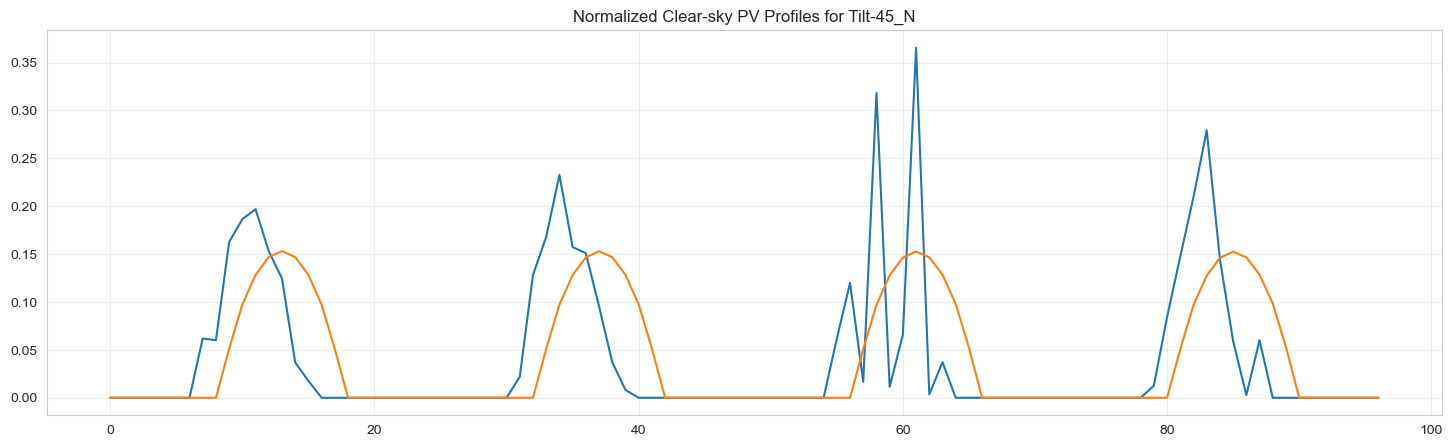

In [20]:
df_profiles_observed_year["tilt-45_N"].loc[0:96].plot(figsize=(18, 5), title="Normalized PV Profiles for Tilt-45_N")
df_profiles_clear_sky["tilt-45_N"].loc[0:96].plot(figsize=(18, 5), title="Normalized Clear-sky PV Profiles for Tilt-45_N")

### Test on one config

In [21]:
pv_3h_df = df_climate_model_2050[['time', "tilt-45_N"]].copy()
pv_3h_df.rename(columns={"tilt-45_N": 'pv'}, inplace=True)

# Disaggregate using observed year profiles
df_out_observed = disaggregate_pv_pd(pv_3h_df, df_profiles_observed_year, "tilt-45_N")
df_out_observed['time'] = df_out_observed['time'] - pd.Timedelta(minutes=30)
df_out_observed

,time,pv_hourly
0,2048-01-01 00:00:00,0.0
1,2048-01-01 01:00:00,0.0
2,2048-01-01 02:00:00,0.0
3,2048-01-01 03:00:00,0.0
4,2048-01-01 04:00:00,0.0
...,...,...
8755,2048-12-31 19:00:00,0.0
8756,2048-12-31 20:00:00,0.0
8757,2048-12-31 21:00:00,0.0
8758,2048-12-31 22:00:00,0.0


In [22]:
pv_3h_df = df_climate_model_2050[['time', "tilt-45_N"]].copy()
pv_3h_df.rename(columns={"tilt-45_N": 'pv'}, inplace=True)

# Disaggregate using clear sky profiles
df_out_clear_sky = disaggregate_pv_pd(pv_3h_df, df_profiles_clear_sky, "tilt-45_N")
df_out_clear_sky['time'] = df_out_clear_sky['time'] - pd.Timedelta(minutes=30)
df_out_clear_sky

,time,pv_hourly
0,2048-01-01 00:00:00,0.0
1,2048-01-01 01:00:00,0.0
2,2048-01-01 02:00:00,0.0
3,2048-01-01 03:00:00,0.0
4,2048-01-01 04:00:00,0.0
...,...,...
8755,2048-12-31 19:00:00,0.0
8756,2048-12-31 20:00:00,0.0
8757,2048-12-31 21:00:00,0.0
8758,2048-12-31 22:00:00,0.0


In [23]:
# Replicate each 3-hourly value into 3 consecutive hourly values
pv_3h_df_hourly = pv_3h_df.copy()
pv_3h_df_hourly['time'] = pd.to_datetime(pv_3h_df_hourly['time'])

hourly_records = []
for idx, row in pv_3h_df_hourly.iterrows():
    center_time = row['time']
    pv_val = row['pv']
    # Generate times: center-1h, center, center+1h
    for offset in [-1, 0, 1]:
        hourly_time = center_time + pd.Timedelta(hours=offset)
        hourly_records.append({'time': hourly_time, 'pv_hourly': pv_val})

df_pv_hourly_replicated = pd.DataFrame(hourly_records)
df_pv_hourly_replicated['time'] = df_pv_hourly_replicated['time'] - pd.Timedelta(minutes=30)

Text(0.5, 0, 'Time')

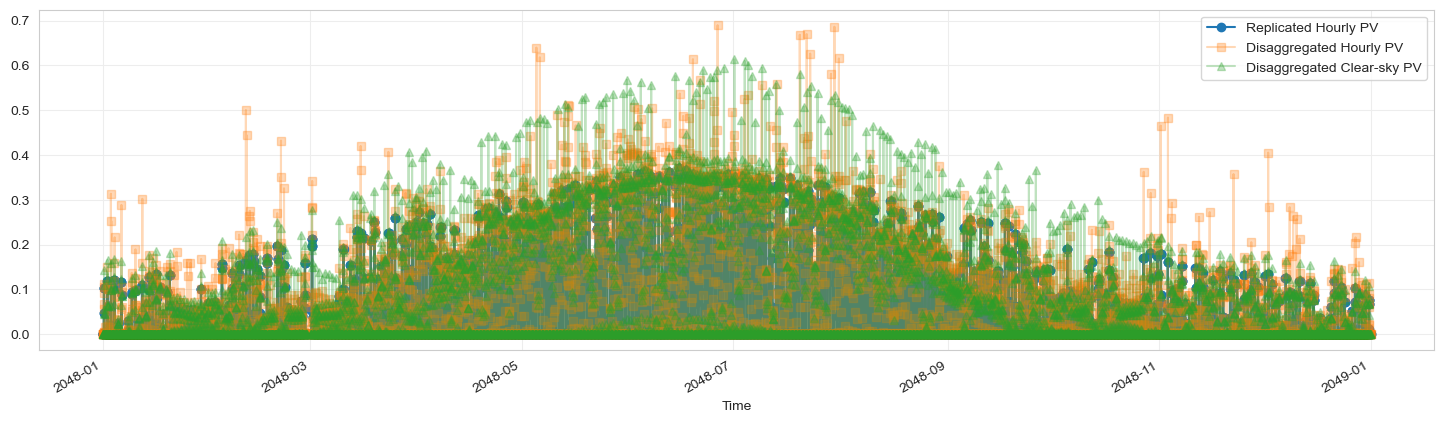

In [24]:
fig, ax = plt.subplots(figsize=(18, 5))
df_pv_hourly_replicated.plot(x='time', y='pv_hourly', label='Replicated Hourly PV', marker='o', ax=ax)
df_out_observed.plot(x='time', y='pv_hourly', label='Disaggregated Hourly PV', marker='s', ax=ax, alpha=0.3)
df_out_clear_sky.plot(x='time', y='pv_hourly', label='Disaggregated Clear-sky PV', marker='^', ax=ax, alpha=0.3)
ax.set_xlabel('Time')

### Apply to all configs

In [25]:
results_observed = []
results_clear_sky = []
pv_columns = [col for col in df_observed_year_pv.columns if col not in ['time', 'dayofyear']]

for col in pv_columns:
    print(f"Processing config: {col}")
    # Prepare input DataFrame for disaggregation
    pv_3h_df = df_climate_model_2050[['time', col]].copy()
    pv_3h_df.rename(columns={col: 'pv'}, inplace=True)

    # Disaggregate using observed year profiles
    df_out_observed = disaggregate_pv_pd(pv_3h_df, df_profiles_observed_year, col)
    df_out_observed.rename(columns={'pv_hourly': col}, inplace=True)
    df_out_observed['time'] = df_out_observed['time'] - pd.Timedelta(minutes=30)
    results_observed.append(df_out_observed[['time', col]])

    # # Disaggregate using clear-sky profiles
    df_out_clear = disaggregate_pv_pd(pv_3h_df, df_profiles_clear_sky, col)
    df_out_clear.rename(columns={'pv_hourly': col}, inplace=True)
    df_out_clear['time'] = df_out_clear['time'] - pd.Timedelta(minutes=30)
    results_clear_sky.append(df_out_clear[['time', col]])

df_observed_all = pd.concat(results_observed, axis=1)
df_clear_sky_all = pd.concat(results_clear_sky, axis=1)

df_observed_all = df_observed_all.loc[:, ~df_observed_all.columns.duplicated()]
df_clear_sky_all = df_clear_sky_all.loc[:, ~df_clear_sky_all.columns.duplicated()]

Processing config: tilt-3_N
Processing config: tilt-8_N
Processing config: tilt-15_N
Processing config: tilt-25_N
Processing config: tilt-35_N
Processing config: tilt-45_N
Processing config: tilt-60_N
Processing config: tilt-80_N
Processing config: tilt-3_E
Processing config: tilt-8_E
Processing config: tilt-15_E
Processing config: tilt-25_E
Processing config: tilt-35_E
Processing config: tilt-45_E
Processing config: tilt-60_E
Processing config: tilt-80_E
Processing config: tilt-3_SE
Processing config: tilt-8_SE
Processing config: tilt-15_SE
Processing config: tilt-25_SE
Processing config: tilt-35_SE
Processing config: tilt-45_SE
Processing config: tilt-60_SE
Processing config: tilt-80_SE
Processing config: tilt-3_S
Processing config: tilt-8_S
Processing config: tilt-15_S
Processing config: tilt-25_S
Processing config: tilt-35_S
Processing config: tilt-45_S
Processing config: tilt-60_S
Processing config: tilt-80_S
Processing config: tilt-3_SW
Processing config: tilt-8_SW
Processing con

In [ ]:
df_observed_all.to_csv(path_energy_ch / "nexus-e" / "observed_profile_pv_hourly.csv", index=False)
df_clear_sky_all.to_csv(path_energy_ch / "nexus-e" / "clear_sky_profile_pv_hourly.csv", index=False)

### Analysis and comparison

In [26]:
annual_sum_observed = df_observed_all.drop('time', axis=1).sum()
annual_sum_clear = df_clear_sky_all.drop('time', axis=1).sum()

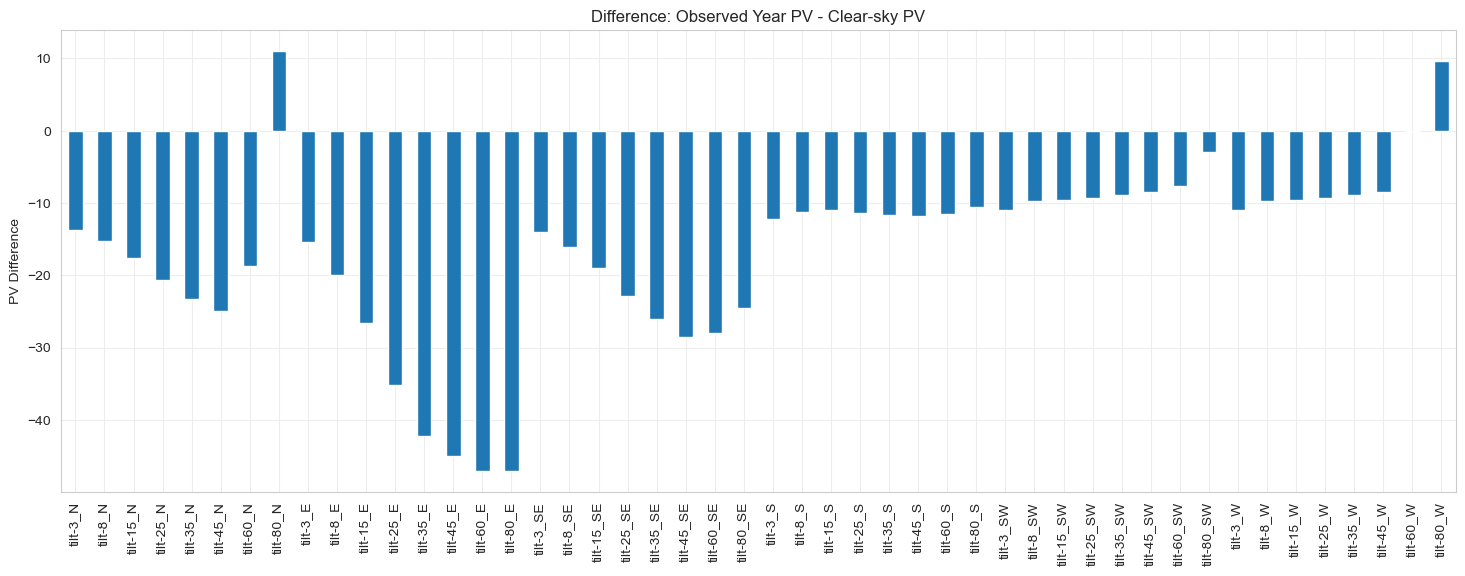

In [27]:
diff = annual_sum_clear - annual_sum_observed
diff.plot.bar(figsize=(18, 6), title="Difference: Observed Year PV - Clear-sky PV")
plt.ylabel("PV Difference")
plt.show()

In [28]:
df_observed_all['month'] = pd.to_datetime(df_observed_all['time']).dt.month
df_clear_sky_all['month'] = pd.to_datetime(df_clear_sky_all['time']).dt.month

monthly_sum_observed = df_observed_all.drop('time', axis=1).groupby('month').sum()
monthly_sum_clear = df_clear_sky_all.drop('time', axis=1).groupby('month').sum()

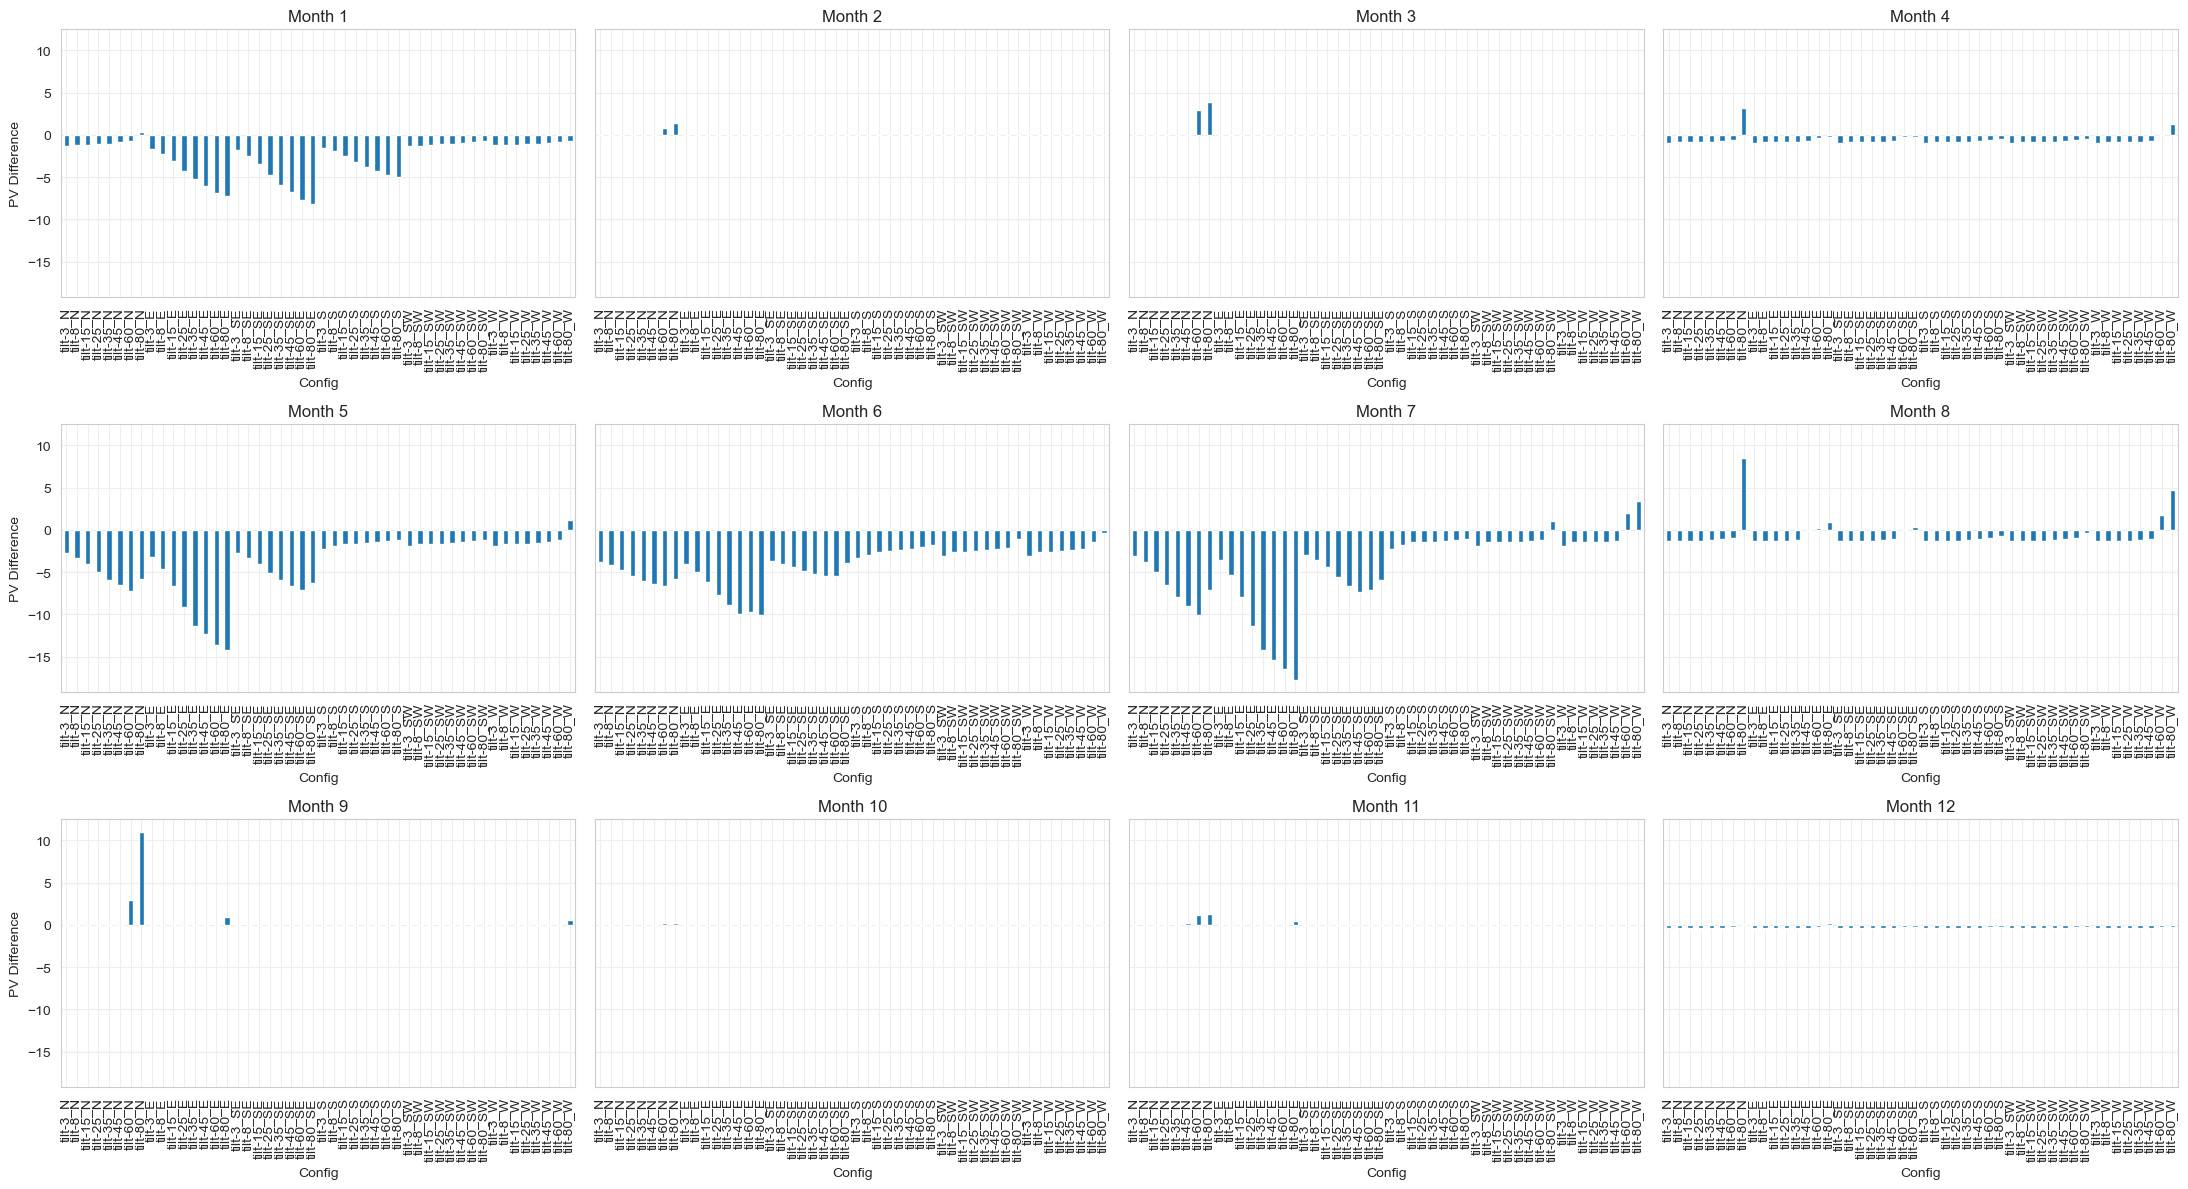

In [29]:
fig, axes = plt.subplots(3, 4, figsize=(22, 12), sharey=True)
months = range(1, 13)

for i, month in enumerate(months):
    ax = axes.flat[i]
    diff_month = monthly_sum_clear.loc[month] - monthly_sum_observed.loc[month]
    diff_month.plot.bar(ax=ax)
    ax.set_title(f"Month {month}")
    ax.set_xlabel("Config")
    ax.set_ylabel("PV Difference" if i % 4 == 0 else "")
    ax.tick_params(axis='x', labelrotation=90)

plt.tight_layout()
plt.show()

In [30]:
def mode_peak_hour(df):
    df['hour'] = pd.to_datetime(df['time']).dt.hour
    df['dayofyear'] = df.index // 24 + 1
    peak_hours = {}
    for col in df.columns:
        if col in ['time', 'month', 'dayofyear', 'hour']:
            continue
        # For each month, find the most frequent hour of daily peak
        monthly_peaks = df.groupby(['month', 'dayofyear'])[[col, 'hour']].apply(
            lambda x: x[[col, 'hour']].sort_values(col, ascending=False).iloc[0]['hour']
        )
        peak_hours[col] = monthly_peaks.groupby('month').agg(lambda x: x.mode().iloc[0])
    return pd.DataFrame(peak_hours)

peak_hour_observed_mode = mode_peak_hour(df_observed_all)
peak_hour_clear_mode = mode_peak_hour(df_clear_sky_all)

In [31]:
peak_hour_observed_mode

,tilt-3_N,tilt-8_N,tilt-15_N,tilt-25_N,tilt-35_N,tilt-45_N,tilt-60_N,tilt-80_N,tilt-3_E,tilt-8_E,...,tilt-60_SW,tilt-80_SW,tilt-3_W,tilt-8_W,tilt-15_W,tilt-25_W,tilt-35_W,tilt-45_W,tilt-60_W,tilt-80_W
month,,,,,,,,,,,,,,,,,,,,,
1,11.0,11.0,11.0,12.0,11.0,11.0,11.0,10.0,11.0,11.0,...,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,14.0
2,12.0,12.0,11.0,11.0,8.0,8.0,8.0,11.0,11.0,11.0,...,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,15.0
3,11.0,11.0,11.0,11.0,8.0,12.0,11.0,11.0,11.0,11.0,...,12.0,12.0,11.0,12.0,12.0,12.0,12.0,12.0,15.0,15.0
4,12.0,11.0,11.0,12.0,11.0,12.0,9.0,9.0,12.0,11.0,...,13.0,13.0,12.0,12.0,12.0,12.0,13.0,13.0,13.0,13.0
5,12.0,12.0,12.0,12.0,11.0,12.0,5.0,5.0,12.0,11.0,...,12.0,12.0,12.0,12.0,12.0,12.0,12.0,13.0,14.0,15.0
6,11.0,11.0,11.0,11.0,11.0,11.0,5.0,5.0,11.0,11.0,...,12.0,12.0,11.0,12.0,12.0,12.0,12.0,12.0,14.0,14.0
7,11.0,11.0,11.0,11.0,11.0,5.0,5.0,5.0,11.0,10.0,...,12.0,11.0,11.0,11.0,12.0,12.0,12.0,12.0,14.0,15.0
8,12.0,12.0,11.0,11.0,11.0,11.0,9.0,6.0,11.0,12.0,...,12.0,13.0,12.0,12.0,12.0,12.0,12.0,14.0,14.0,15.0
9,12.0,12.0,12.0,11.0,11.0,8.0,11.0,6.0,12.0,12.0,...,13.0,15.0,12.0,12.0,12.0,12.0,15.0,15.0,15.0,15.0


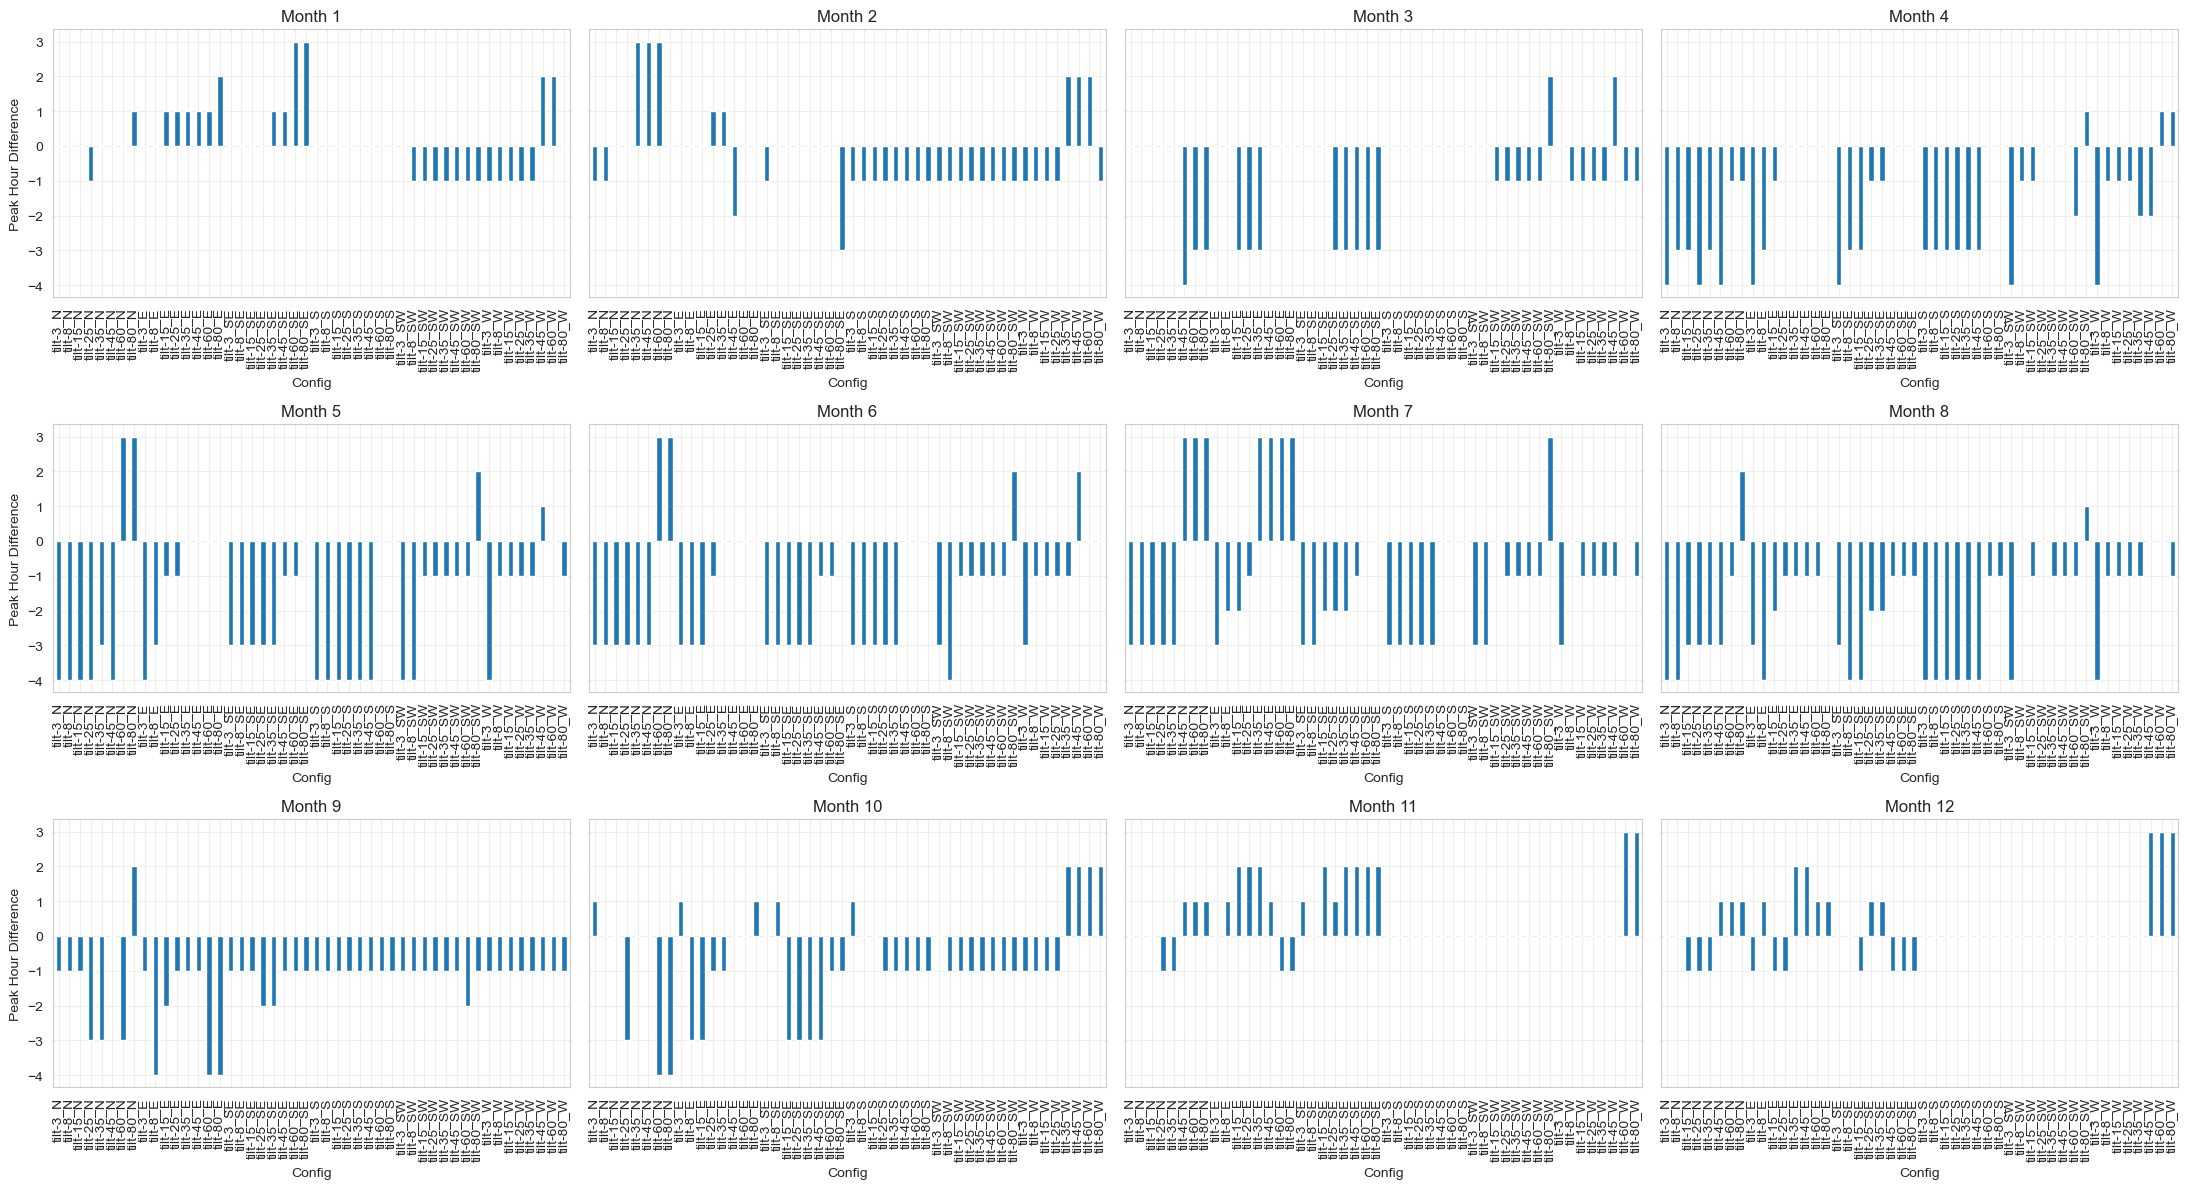

In [32]:
fig, axes = plt.subplots(3, 4, figsize=(22, 12), sharey=True)
months = range(1, 13)

for i, month in enumerate(months):
    ax = axes.flat[i]
    diff_month = peak_hour_clear_mode.loc[month] - peak_hour_observed_mode.loc[month]
    diff_month.plot.bar(ax=ax)
    ax.set_title(f"Month {month}")
    ax.set_xlabel("Config")
    ax.set_ylabel("Peak Hour Difference" if i % 4 == 0 else "")
    ax.tick_params(axis='x', labelrotation=90)

plt.tight_layout()
plt.show()

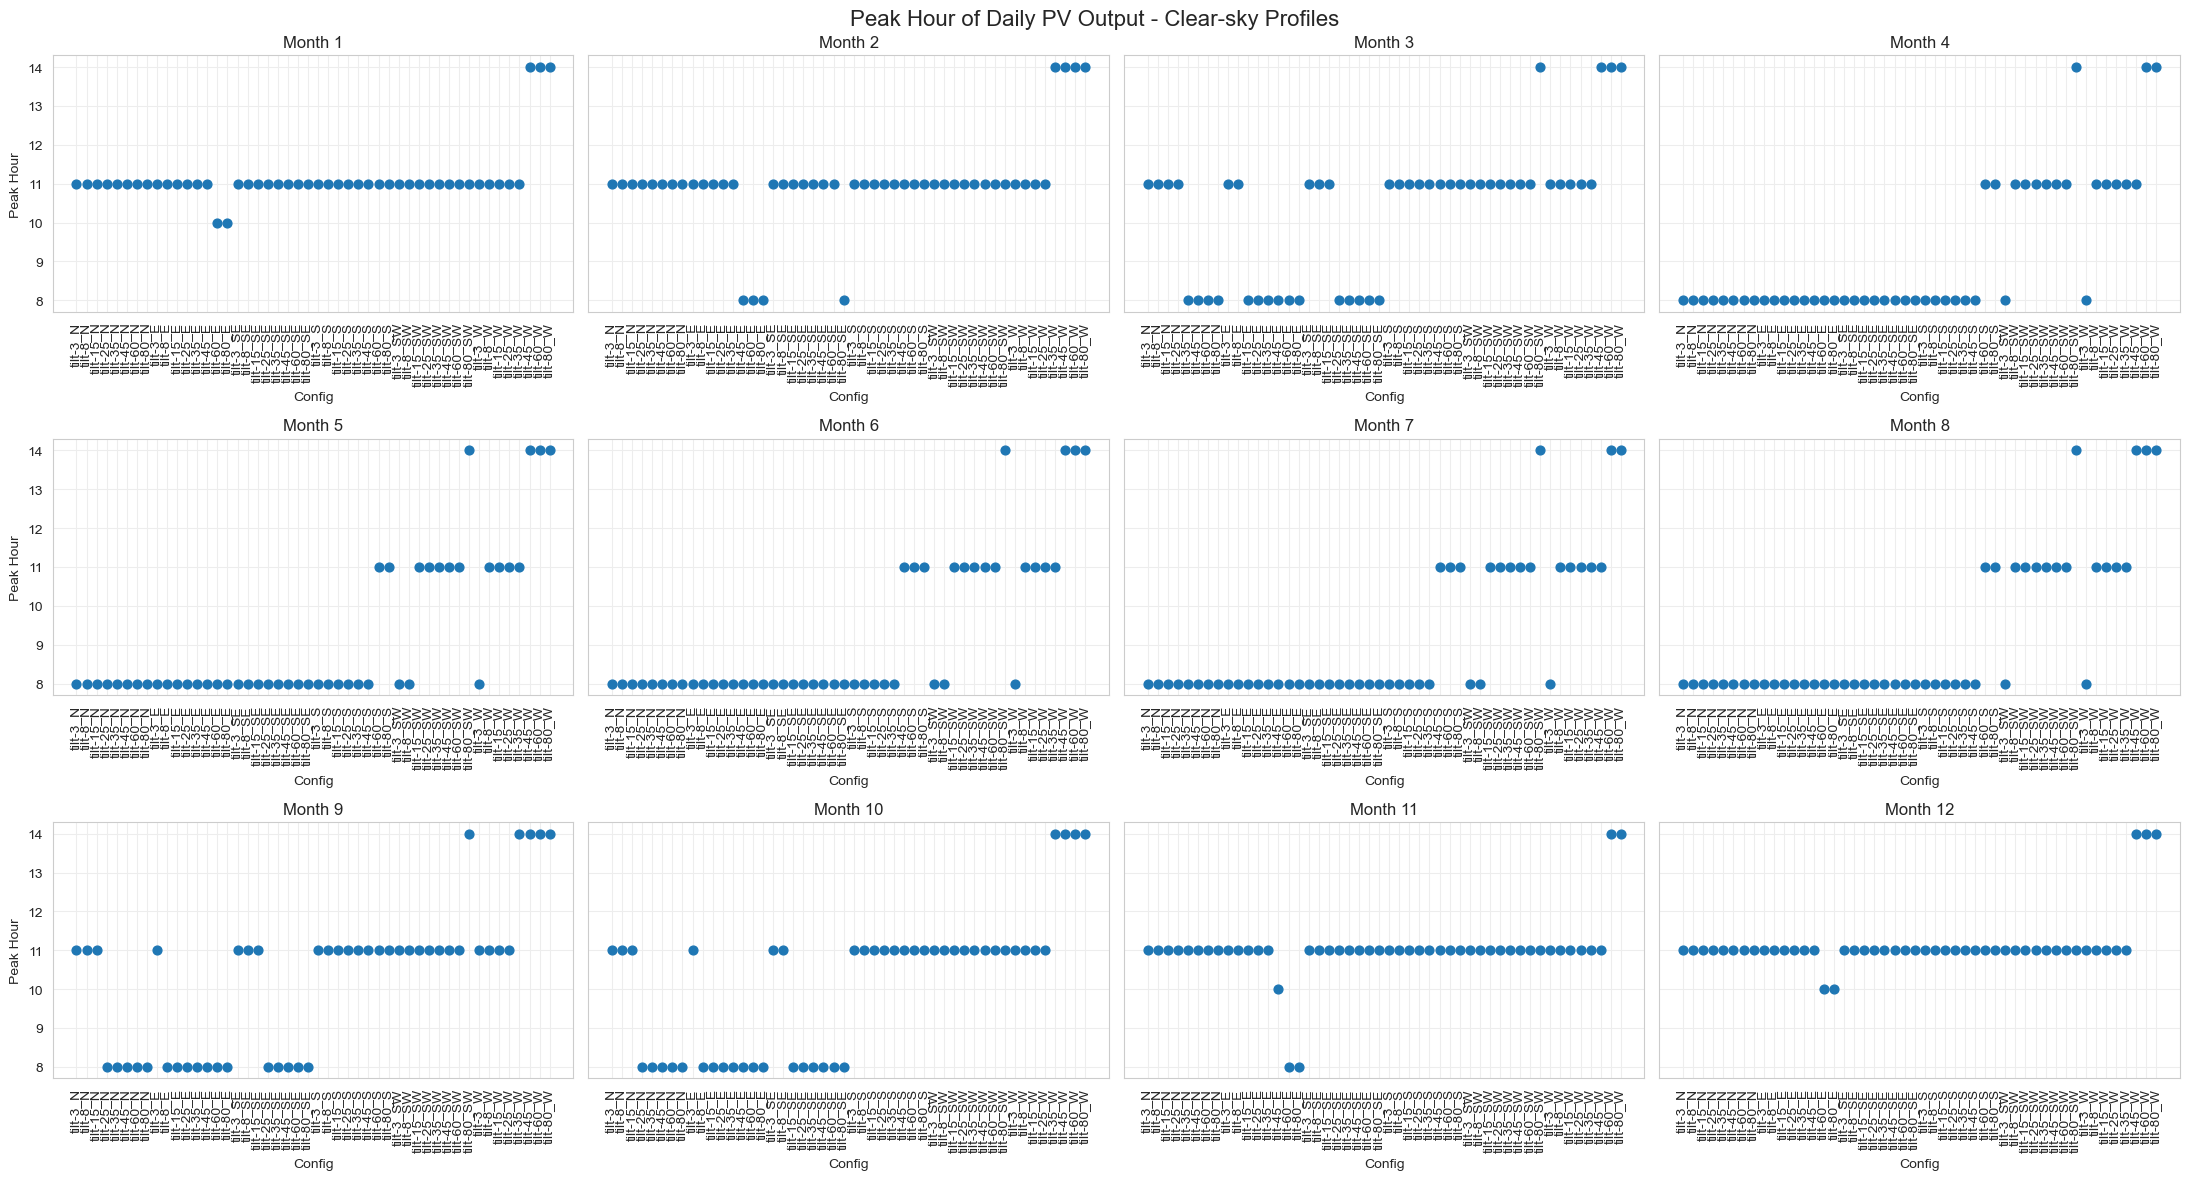

In [38]:
fig, axes = plt.subplots(3, 4, figsize=(22, 12), sharey=True)
months = range(1, 13)

for i, month in enumerate(months):
    ax = axes.flat[i]
    ax.scatter(peak_hour_clear_mode.columns, peak_hour_clear_mode.loc[month], color='C0', s=40)
    ax.set_title(f"Month {month}")
    ax.set_xlabel("Config")
    ax.set_ylabel("Peak Hour" if i % 4 == 0 else "")
    ax.tick_params(axis='x', labelrotation=90)

plt.suptitle("Peak Hour of Daily PV Output - Clear-sky Profiles", fontsize=16)
plt.tight_layout()
plt.show()

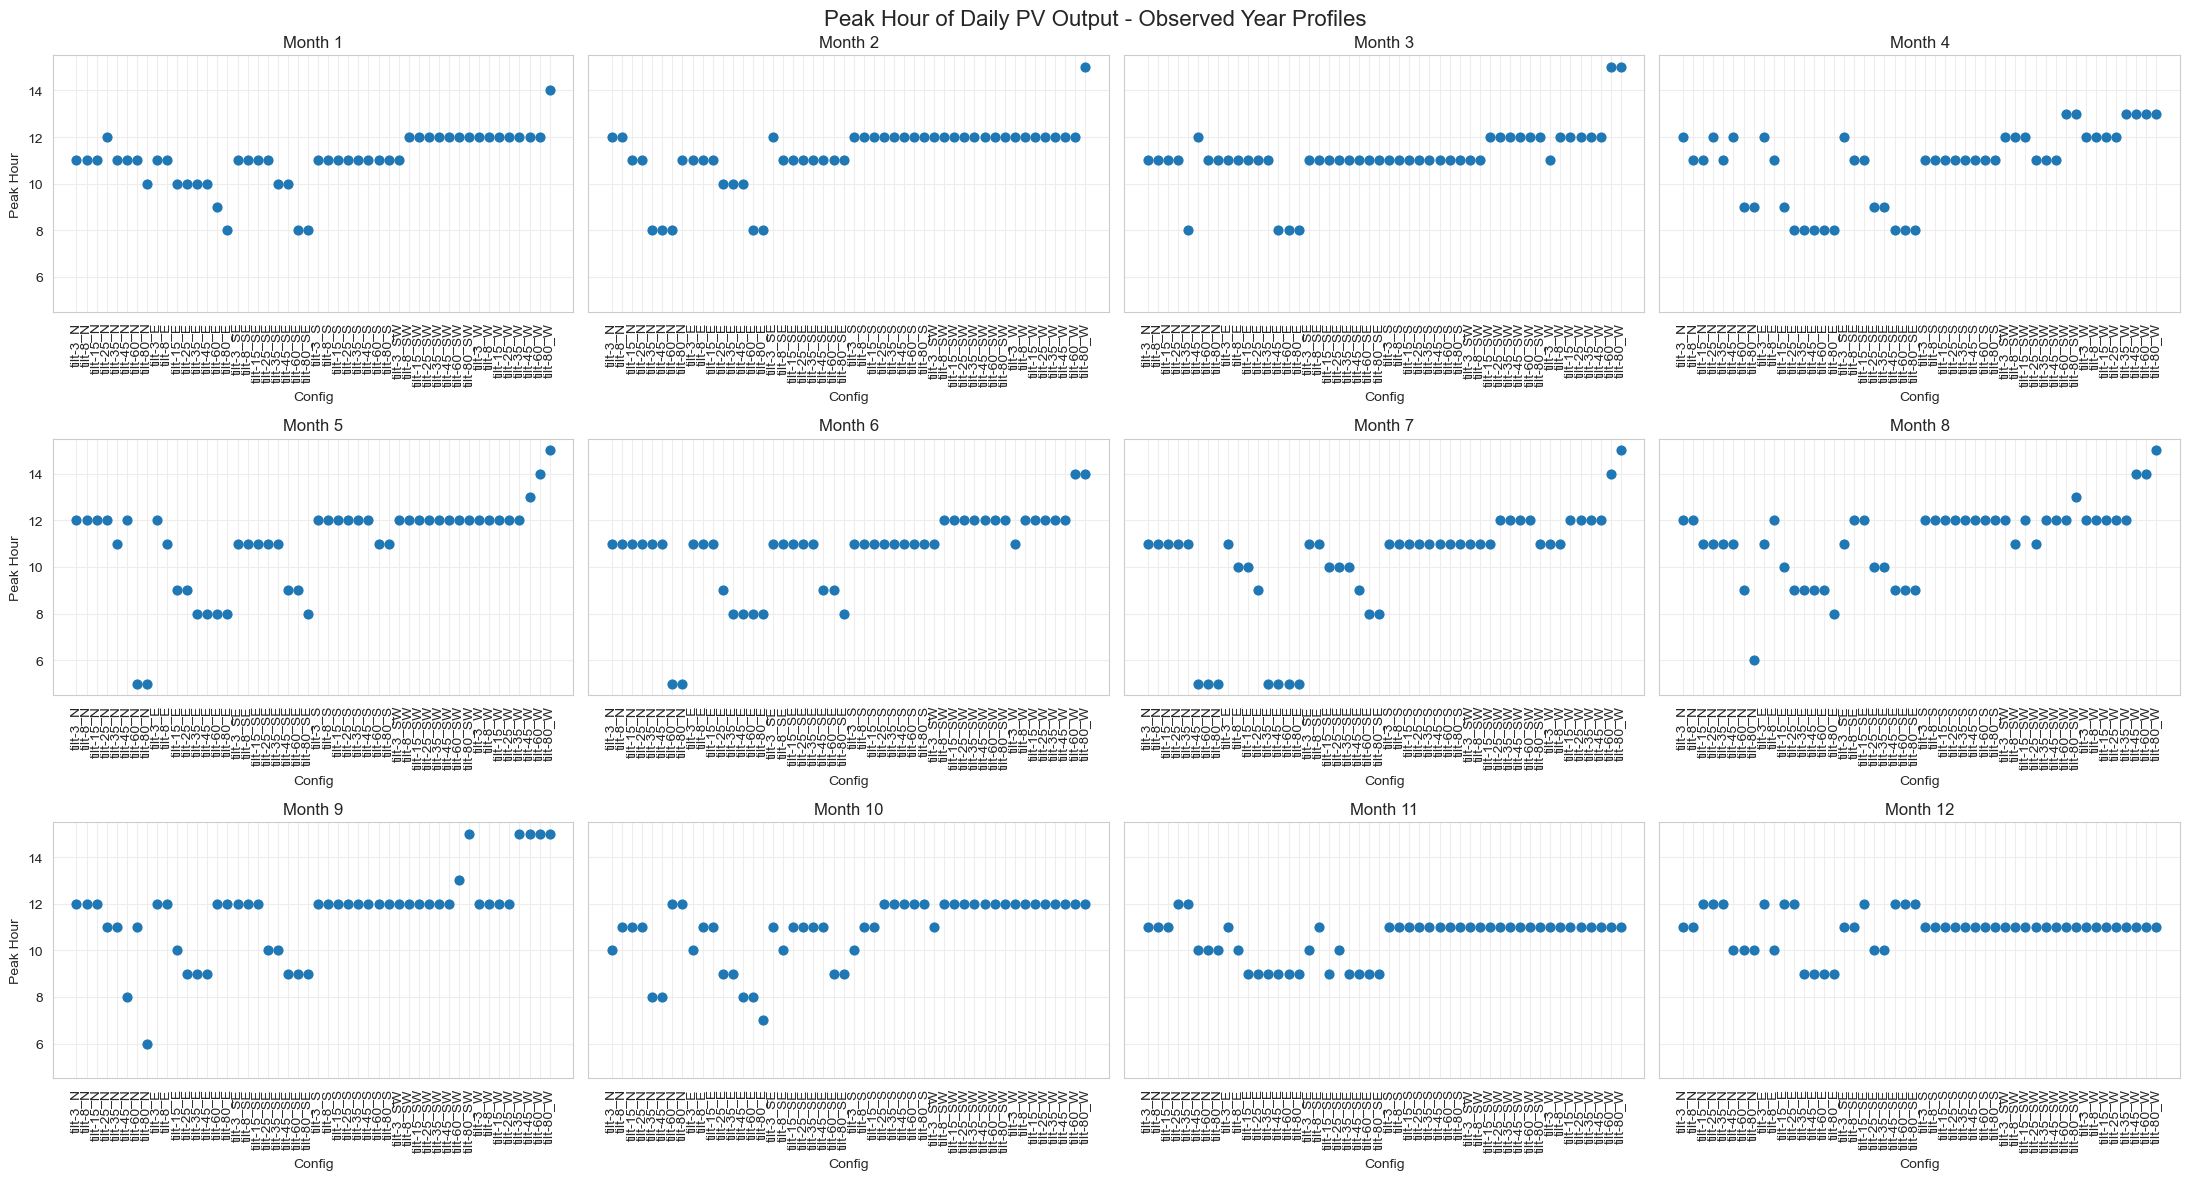

In [39]:
fig, axes = plt.subplots(3, 4, figsize=(22, 12), sharey=True)
months = range(1, 13)

for i, month in enumerate(months):
    ax = axes.flat[i]
    ax.scatter(peak_hour_observed_mode.columns, peak_hour_observed_mode.loc[month], color='C0', s=40)
    ax.set_title(f"Month {month}")
    ax.set_xlabel("Config")
    ax.set_ylabel("Peak Hour" if i % 4 == 0 else "")
    ax.tick_params(axis='x', labelrotation=90)

plt.suptitle("Peak Hour of Daily PV Output - Observed Year Profiles", fontsize=16)
plt.tight_layout()
plt.show()